# Laboratorio 11 – Preprocesamiento de imágenes

**Curso**: Software Inteligente — UNMSM · **Estudiante**: Angela Jara

## 0. Objetivo y enunciado

**Enunciado (Laboratorio Semana 11):**

> - Considerar un conjunto de imágenes de algún tipo o problema, considere 3 clases en carpetas diferentes.
> - Aplique preprocesamiento a un conjunto de imágenes: filtro promedio, filtro gaussiano, filtro no lineal, rotación, traslación, escalado.
>
> Somete a un conjunto de imágenes trivialmente como resultado obtiene nuevas imágenes.

**Objetivo**: tomar un conjunto de imágenes de un problema real de visión (reconocimiento de gestos
de *piedra, papel o tijera*), organizado en 3 carpetas (una por clase), aplicarle seis operaciones de
preprocesamiento —tres filtros y tres transformaciones geométricas— y obtener como resultado un
**nuevo conjunto de imágenes** guardado en disco, explicando el efecto de cada operación.

**Enfoque**: se usa OpenCV para cada operación con parámetros declarados en una sola celda de
configuración; se comparan visualmente original y resultado por clase; se mide con PSNR el efecto de
los filtros sobre imágenes con ruido; y finalmente se genera y verifica el conjunto nuevo
(30 originales × 6 operaciones = 180 imágenes).

### Trazabilidad enunciado → secciones

| Requisito del enunciado | Sección del notebook |
|---|---|
| Conjunto de imágenes de un problema, 3 clases en carpetas diferentes | §2 Conjunto de datos, §3 Carga y exploración |
| Filtro promedio | §4 Fundamentos, §5 Filtros |
| Filtro gaussiano | §4 Fundamentos, §5 Filtros |
| Filtro no lineal (mediana) | §4 Fundamentos, §5 Filtros, §6 Experimento con ruido |
| Rotación | §4 Fundamentos, §7 Transformaciones geométricas |
| Traslación | §4 Fundamentos, §7 Transformaciones geométricas |
| Escalado | §4 Fundamentos, §7 Transformaciones geométricas |
| Como resultado se obtienen nuevas imágenes | §8 Generación del nuevo conjunto, §9 Resumen y verificación |

### Cómo ejecutar

```bash
cd lab11
uv sync                      # crea el entorno (Python 3.14) a partir de uv.lock
uv run jupyter execute --inplace laboratorio11_preprocesamiento_imagenes.ipynb   # o abrirlo en Jupyter/VS Code
```

El notebook funciona **sin conexión**: el subconjunto de imágenes está incluido en `data/`. Las
imágenes generadas se escriben en `output/` (se regenera en cada ejecución y no se versiona).

## 1. Configuración

Todas las rutas son relativas a la carpeta `lab11/` y todos los parámetros de las operaciones se
declaran aquí, de modo que cualquier cambio se haga en un único lugar.

In [1]:
import platform
import random
import shutil
import tempfile
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Reproducibilidad y rutas -------------------------------------------------
SEMILLA = 42
DIR_DATOS = Path("data")
DIR_SALIDA = Path("output")
URL_DATASET = "https://storage.googleapis.com/download.tensorflow.org/data/rps.zip"
REGENERAR_SUBCONJUNTO = False  # True solo para volver a descargar y muestrear (requiere internet)

# --- Conjunto de datos --------------------------------------------------------
CLASES = ("rock", "paper", "scissors")
N_POR_CLASE = 10
EXTENSIONES = {".png", ".jpg", ".jpeg"}

# --- Filtros ------------------------------------------------------------------
K_PROMEDIO = 5        # tamaño de la ventana del filtro promedio (5x5)
K_GAUSS = 5           # tamaño del kernel gaussiano (5x5)
SIGMA_GAUSS = 1.0     # desviación estándar del kernel gaussiano
K_MEDIANA = 5         # tamaño de la ventana del filtro de mediana (5x5)
PROP_RUIDO = 0.05     # proporción de píxeles afectados por ruido sal y pimienta

# --- Transformaciones geométricas --------------------------------------------
ANGULO = 45                  # grados, sentido antihorario, alrededor del centro
TX = TY = 60                 # desplazamiento en píxeles (20 % de 300)
FACTOR_ESCALA = 0.5          # escalado que se guarda en el nuevo conjunto
FACTOR_AMPLIACION = 1.5      # ampliación solo para comparar (no se guarda)
COLOR_BORDE = (255, 255, 255)  # relleno blanco, igual que el fondo del dataset

np.random.seed(SEMILLA)
random.seed(SEMILLA)

print(f"Python      {platform.python_version()}")
print(f"OpenCV      {cv2.__version__}")
print(f"NumPy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"Matplotlib  {matplotlib.__version__}")

Python      3.14.4
OpenCV      5.0.0
NumPy       2.5.4
pandas      3.1.0
Matplotlib  3.11.2


In [2]:
def mostrar_grilla(imagenes, titulos, filas, columnas, titulo_figura, tam_celda=3.0, lienzo=None):
    """Muestra imágenes BGR (o en gris) en una grilla; con `lienzo` todas comparten la misma escala en píxeles."""
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * tam_celda, filas * tam_celda), squeeze=False)
    for eje in ejes.flat:
        eje.axis("off")
    for eje, img, titulo in zip(ejes.flat, imagenes, titulos):
        alto, ancho = img.shape[:2]
        extension = (0, ancho, alto, 0)
        if img.ndim == 2:
            eje.imshow(img, cmap="gray", vmin=0, vmax=255, extent=extension)
        else:
            eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), extent=extension)
        if lienzo is not None:
            eje.set_xlim(0, lienzo)
            eje.set_ylim(lienzo, 0)
        eje.set_title(titulo, fontsize=9)
    fig.suptitle(titulo_figura, fontsize=12)
    fig.tight_layout()
    plt.show()

## 2. Conjunto de datos

**Problema**: reconocimiento de gestos de la mano para el juego *piedra, papel o tijera*. Cada imagen
muestra una mano generada por computadora (CGI) haciendo uno de los tres gestos sobre fondo blanco,
con distintos tonos de piel y posiciones. Es un problema de clasificación de 3 clases y las imágenes
ya vienen organizadas **en una carpeta por clase**: `rock` (piedra), `paper` (papel) y `scissors`
(tijera).

**Fuente y licencia**: *Rock Paper Scissors Dataset*, Laurence Moroney
(<https://laurencemoroney.com/datasets.html>), licencia **CC BY 2.0**. Partición de entrenamiento
(840 imágenes por clase, PNG de 300×300 px).

**Subconjunto usado**: para que el laboratorio sea liviano, reproducible y no requiera internet, se
incluyen en `data/<clase>/` **10 imágenes por clase (30 en total)**, elegidas con
`random.Random(42).sample` sobre la lista ordenada de archivos de cada clase y copiadas sin
modificar (ver `data/ATTRIBUTION.md`). La lista exacta se declara abajo; la celda siguiente permite
regenerarla si `REGENERAR_SUBCONJUNTO = True`.

In [3]:
SUBCONJUNTO = {
    "rock": [
        "rock01-025.png",
        "rock01-104.png",
        "rock01-114.png",
        "rock02-022.png",
        "rock02-108.png",
        "rock03-010.png",
        "rock03-041.png",
        "rock06ck02-054.png",
        "rock07-k03-034.png",
        "rock07-k03-039.png"
    ],
    "paper": [
        "paper01-030.png",
        "paper01-032.png",
        "paper01-089.png",
        "paper01-095.png",
        "paper02-103.png",
        "paper04-072.png",
        "paper05-078.png",
        "paper06-004.png",
        "paper06-092.png",
        "paper07-038.png"
    ],
    "scissors": [
        "scissors01-027.png",
        "scissors02-083.png",
        "scissors02-118.png",
        "testscissors01-037.png",
        "testscissors01-078.png",
        "testscissors01-094.png",
        "testscissors02-016.png",
        "testscissors02-065.png",
        "testscissors02-118.png",
        "testscissors03-013.png"
    ]
}

print({clase: len(nombres) for clase, nombres in SUBCONJUNTO.items()})

{'rock': 10, 'paper': 10, 'scissors': 10}


In [4]:
def regenerar_subconjunto(url, dir_datos, clases, n, semilla):
    """Descarga el dataset completo y copia n imágenes por clase elegidas con una semilla fija."""
    with tempfile.TemporaryDirectory() as tmp:
        ruta_zip = Path(tmp) / "rps.zip"
        urllib.request.urlretrieve(url, ruta_zip)
        with zipfile.ZipFile(ruta_zip) as zf:
            zf.extractall(tmp)
        rng = random.Random(semilla)
        seleccion = {}
        for clase in clases:
            origen = Path(tmp) / "rps" / clase
            nombres = sorted(p.name for p in origen.glob("*.png"))
            seleccion[clase] = sorted(rng.sample(nombres, n))
            destino = dir_datos / clase
            destino.mkdir(parents=True, exist_ok=True)
            for nombre in seleccion[clase]:
                shutil.copy2(origen / nombre, destino / nombre)
    return seleccion


if REGENERAR_SUBCONJUNTO:
    seleccion = regenerar_subconjunto(URL_DATASET, DIR_DATOS, CLASES, N_POR_CLASE, SEMILLA)
    assert seleccion == SUBCONJUNTO, "La selección regenerada no coincide con SUBCONJUNTO"
    print("Subconjunto regenerado y verificado.")
else:
    print("Se usa el subconjunto incluido en data/ (REGENERAR_SUBCONJUNTO = False).")

faltantes = [clase for clase in CLASES if not (DIR_DATOS / clase).is_dir()]
if faltantes:
    raise FileNotFoundError(
        f"No se encontraron las carpetas {[str(DIR_DATOS / c) for c in faltantes]}. "
        f"Se esperan las carpetas data/rock, data/paper y data/scissors. "
        f"Ponga REGENERAR_SUBCONJUNTO = True o descargue el dataset desde {URL_DATASET}."
    )
for clase in CLASES:
    presentes = sorted(p.name for p in (DIR_DATOS / clase).glob("*.png"))
    if presentes != SUBCONJUNTO[clase]:
        print(f"Aviso: los archivos de data/{clase} no coinciden exactamente con SUBCONJUNTO.")
print("Carpetas de clases encontradas:", [str(DIR_DATOS / c) for c in CLASES])

Se usa el subconjunto incluido en data/ (REGENERAR_SUBCONJUNTO = False).
Carpetas de clases encontradas: ['data/rock', 'data/paper', 'data/scissors']


## 3. Carga y exploración

Cada imagen se lee con `cv2.imread(..., cv2.IMREAD_COLOR)`, que devuelve un arreglo `uint8` de
alto × ancho × 3 en orden de canales **BGR** (el canal alfa de los PNG se descarta). La clase se toma
del nombre de la carpeta. Los archivos que no son imágenes o no se pueden leer se omiten y se
informan.

In [5]:
def cargar_dataset(dir_datos, clases):
    """Lee las imágenes de cada carpeta de clase; devuelve (registros, archivos_omitidos)."""
    registros, omitidos = [], []
    for clase in clases:
        for ruta in sorted((dir_datos / clase).iterdir()):
            if not ruta.is_file():
                continue
            pixeles = cv2.imread(str(ruta), cv2.IMREAD_COLOR) if ruta.suffix.lower() in EXTENSIONES else None
            if pixeles is None:
                omitidos.append(str(ruta))
                continue
            registros.append({"clase": clase, "nombre": ruta.name, "ruta": ruta, "pixeles": pixeles})
    return registros, omitidos


imagenes, omitidos = cargar_dataset(DIR_DATOS, CLASES)
print(f"Imágenes cargadas: {len(imagenes)}")
print(f"Archivos omitidos: {omitidos if omitidos else 'ninguno'}")

Imágenes cargadas: 30
Archivos omitidos: ninguno


In [6]:
resumen = (
    pd.DataFrame(
        {
            "clase": r["clase"],
            "forma": "×".join(map(str, r["pixeles"].shape)),
            "dtype": str(r["pixeles"].dtype),
        }
        for r in imagenes
    )
    .groupby("clase", sort=False)
    .agg(n_imagenes=("forma", "size"), formas=("forma", lambda s: ", ".join(sorted(set(s)))), dtype=("dtype", "first"))
)
display(resumen)

assert len(CLASES) == 3, "El laboratorio requiere exactamente 3 clases"
for clase in CLASES:
    n = int(resumen.loc[clase, "n_imagenes"]) if clase in resumen.index else 0
    assert n == N_POR_CLASE, f"La clase '{clase}' tiene {n} imágenes; se esperaban {N_POR_CLASE}"
distintas = [r["nombre"] for r in imagenes if r["pixeles"].shape != (300, 300, 3)]
if distintas:
    print(f"Aviso: imágenes con tamaño distinto de 300×300×3 (se procesan tal cual): {distintas}")
else:
    print("Todas las imágenes son de 300×300 px con 3 canales.")

,n_imagenes,formas,dtype
clase,,,
rock,10,300×300×3,uint8
paper,10,300×300×3,uint8
scissors,10,300×300×3,uint8


Todas las imágenes son de 300×300 px con 3 canales.


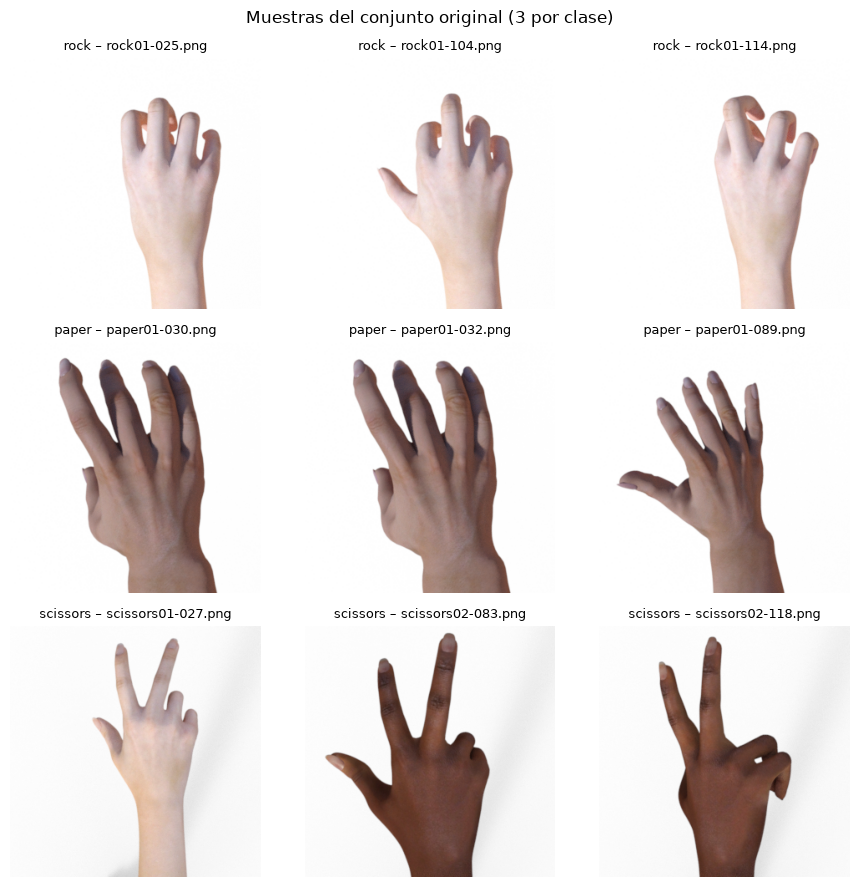

In [7]:
muestras = [r for clase in CLASES for r in [x for x in imagenes if x["clase"] == clase][:3]]
mostrar_grilla(
    [r["pixeles"] for r in muestras],
    [f"{r['clase']} – {r['nombre']}" for r in muestras],
    filas=3, columnas=3, titulo_figura="Muestras del conjunto original (3 por clase)",
)

**Interpretación.** Las tres clases son visualmente distinguibles: *rock* (puño o dedos recogidos), *paper* (mano abierta con dedos extendidos) y *scissors* (índice y medio en V). Todas las imágenes son de 300×300 px sobre un fondo blanco o gris muy claro, con variedad de tonos de piel y de ángulo de la mano. El fondo uniforme hace que el efecto de cada operación se aprecie con claridad, en especial en los contornos de los dedos.

## 4. Fundamentos

### 4.1 Filtrado espacial y convolución

Un filtro espacial lineal reemplaza cada píxel por una **combinación ponderada de sus vecinos**. Los
pesos forman un *kernel* $K$ de tamaño $k \times k$ que se desliza sobre la imagen $I$
(convolución / correlación 2D):

$$I'(x,y) = \sum_{i=-r}^{r}\sum_{j=-r}^{r} K(i,j)\, I(x+i,\, y+j), \qquad r = \lfloor k/2 \rfloor$$

En imágenes a color la operación se aplica a cada canal por separado. En los bordes OpenCV
completa los vecinos que faltan reflejando la imagen.

**Filtro promedio (caja).** Todos los pesos son iguales y suman 1. Con $k = 5$:

$$K_{\text{prom}} = \frac{1}{25}\begin{bmatrix}1 & 1 & \cdots & 1\\ \vdots & & & \vdots\\ 1 & 1 & \cdots & 1\end{bmatrix}_{5\times 5}$$

Suaviza la imagen y reduce ruido, pero también desdibuja los bordes por igual.

**Filtro gaussiano.** Los pesos siguen una campana gaussiana 2D, de modo que los vecinos cercanos
pesan más que los lejanos:

$$G(x,y) = \frac{1}{2\pi\sigma^2}\, e^{-\frac{x^2+y^2}{2\sigma^2}}, \qquad \sigma = 1{,}0,\ \text{kernel } 5\times5\ (\approx \pm 2\sigma)$$

El kernel se normaliza para que sume 1. Suaviza de forma más "natural" que el promedio y conserva
algo mejor las estructuras.

### 4.2 Filtros lineales vs. no lineales

Un filtro $F$ es **lineal** si cumple superposición: $F(a\,I_1 + b\,I_2) = a\,F(I_1) + b\,F(I_2)$.
El promedio y el gaussiano lo cumplen porque son sumas ponderadas.

**Filtro de mediana (no lineal).** Reemplaza cada píxel por la **mediana** de los valores de su
ventana $5\times5$. La mediana es un *estadístico de orden* (se ordenan los valores y se toma el
central), no una suma ponderada; por eso **no cumple superposición** y no puede escribirse como una
convolución. Su ventaja: un píxel atípico (p. ej., ruido sal y pimienta: 0 o 255) casi nunca queda
en la posición central del ordenamiento, así que se elimina sin promediarse con sus vecinos, y los
bordes se conservan nítidos.

### 4.3 Transformaciones geométricas afines

Una transformación afín mueve cada píxel $(x, y)$ a una nueva posición con una matriz $2\times3$:

$$\begin{bmatrix}x'\\y'\end{bmatrix} = \begin{bmatrix}a_{11} & a_{12} & t_x\\ a_{21} & a_{22} & t_y\end{bmatrix}\begin{bmatrix}x\\y\\1\end{bmatrix}$$

- **Rotación** de ángulo $\theta$ alrededor del centro $(c_x, c_y)$ (`cv2.getRotationMatrix2D`):
  $\begin{bmatrix}\cos\theta & \sin\theta & (1-\cos\theta)c_x - \sin\theta\, c_y\\ -\sin\theta & \cos\theta & \sin\theta\, c_x + (1-\cos\theta)c_y\end{bmatrix}$
- **Traslación** por $(t_x, t_y)$: $\begin{bmatrix}1 & 0 & t_x\\ 0 & 1 & t_y\end{bmatrix}$
- **Escalado** por un factor $s$: $\begin{bmatrix}s & 0 & 0\\ 0 & s & 0\end{bmatrix}$; cambia las dimensiones de
  la imagen (`cv2.resize`). Al **reducir** se usa interpolación `INTER_AREA` (promedia los píxeles
  que se fusionan y evita *aliasing*); al **ampliar**, `INTER_LINEAR` (interpola entre píxeles
  vecinos, pues hay que inventar valores que no existían).

**Bordes.** Tras rotar o trasladar, parte del lienzo queda sin píxel de origen. Hay que decidir con
qué rellenarlo: aquí se usa `BORDER_CONSTANT` con **blanco**, el mismo color del fondo del dataset,
para que el relleno no introduzca bordes artificiales. Alternativas como `BORDER_REFLECT` crearían
"manos fantasma" duplicadas, y el negro generaría contornos que no existen en los datos.

## 5. Filtros

Cada operación se implementa como una función **pura**: recibe una imagen y devuelve una imagen
nueva, sin modificar la original.

In [8]:
def filtro_promedio(img):
    """Filtro lineal de caja: promedio de la ventana K_PROMEDIO×K_PROMEDIO."""
    return cv2.blur(img, (K_PROMEDIO, K_PROMEDIO))


def filtro_gaussiano(img):
    """Filtro lineal gaussiano de K_GAUSS×K_GAUSS con desviación SIGMA_GAUSS."""
    return cv2.GaussianBlur(img, (K_GAUSS, K_GAUSS), SIGMA_GAUSS)


def filtro_mediana(img):
    """Filtro no lineal: mediana de la ventana K_MEDIANA×K_MEDIANA."""
    return cv2.medianBlur(img, K_MEDIANA)


FILTROS = {
    f"promedio {K_PROMEDIO}×{K_PROMEDIO}": filtro_promedio,
    f"gaussiano {K_GAUSS}×{K_GAUSS} σ={SIGMA_GAUSS}": filtro_gaussiano,
    f"mediana {K_MEDIANA}×{K_MEDIANA}": filtro_mediana,
}

# Kernel gaussiano 1D que usa OpenCV (el 2D es el producto exterior)
g = cv2.getGaussianKernel(K_GAUSS, SIGMA_GAUSS)
print("Kernel gaussiano 5×5 (σ=1):")
print(np.round(g @ g.T, 4))

Kernel gaussiano 5×5 (σ=1):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


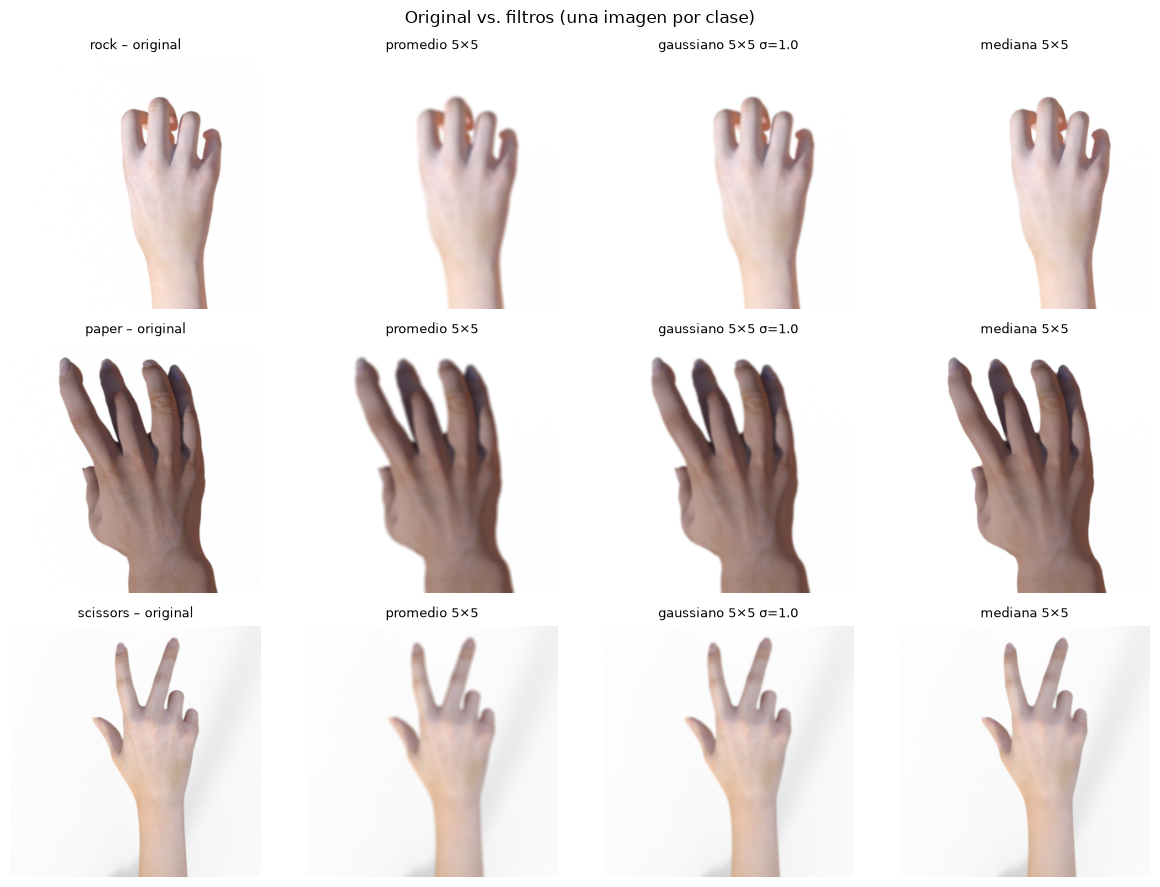

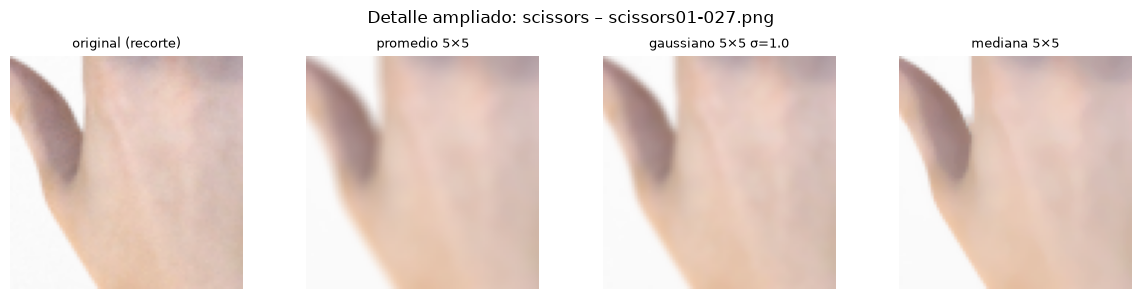

In [9]:
primeras = [next(r for r in imagenes if r["clase"] == clase) for clase in CLASES]

grilla, titulos = [], []
for r in primeras:
    grilla.append(r["pixeles"])
    titulos.append(f"{r['clase']} – original")
    for nombre, filtro in FILTROS.items():
        grilla.append(filtro(r["pixeles"]))
        titulos.append(nombre)
mostrar_grilla(grilla, titulos, filas=3, columnas=4, titulo_figura="Original vs. filtros (una imagen por clase)")

# Recorte ampliado de 80×80 px en la zona central de la mano para apreciar el suavizado
r0 = primeras[2]["pixeles"]
y0, x0, lado = 110, 110, 80
recortes = [r0[y0:y0 + lado, x0:x0 + lado]] + [f(r0)[y0:y0 + lado, x0:x0 + lado] for f in FILTROS.values()]
mostrar_grilla(recortes, ["original (recorte)"] + list(FILTROS), filas=1, columnas=4,
               titulo_figura=f"Detalle ampliado: {primeras[2]['clase']} – {primeras[2]['nombre']}")

In [10]:
# Comprobación numérica de (no) linealidad: F(a + b) vs. F(a) + F(b)
# Se usan dos imágenes en gris divididas entre 2 para que la suma no desborde 255.
a = cv2.cvtColor(primeras[0]["pixeles"], cv2.COLOR_BGR2GRAY) // 2
b = cv2.cvtColor(primeras[1]["pixeles"], cv2.COLOR_BGR2GRAY) // 2

filas_lineal = []
for nombre, filtro in [("promedio", filtro_promedio), ("gaussiano", filtro_gaussiano), ("mediana", filtro_mediana)]:
    f_suma = filtro(a + b).astype(int)
    suma_f = filtro(a).astype(int) + filtro(b).astype(int)
    dif = np.abs(f_suma - suma_f)
    filas_lineal.append({
        "filtro": nombre,
        "dif. máxima (niveles)": int(dif.max()),
        "dif. media (niveles)": round(float(dif.mean()), 3),
        "% píxeles con dif. > 2": round(100 * float((dif > 2).mean()), 2),
    })
tabla_linealidad = pd.DataFrame(filas_lineal).set_index("filtro")
display(tabla_linealidad)

,dif. máxima (niveles),dif. media (niveles),% píxeles con dif. > 2
filtro,,,
promedio,1,0.061,0.00
gaussiano,1,0.061,0.00
mediana,48,0.171,1.07


**Interpretación.**

- **Promedio 5×5**: produce el desenfoque más visible. Los contornos de los dedos y las arrugas de los nudillos se vuelven difusos porque cada píxel se mezcla por igual con sus 24 vecinos.
- **Gaussiano 5×5, σ = 1**: suaviza menos que el promedio con la misma ventana. El kernel impreso concentra el 16,2 % del peso en el píxel central y apenas 0,3 % en las esquinas, así que la textura fina de la piel se atenúa pero los bordes conservan más definición.
- **Mediana 5×5**: los bordes mano/fondo quedan **nítidos** (se ve en el recorte ampliado, borde del pulgar), mientras que las texturas pequeñas, como las líneas de la piel, se aplanan en zonas casi uniformes.

**Comprobación de linealidad**: para promedio y gaussiano, $F(a+b)$ y $F(a)+F(b)$ difieren como máximo en **1 nivel** de intensidad (diferencia media 0,061), que es solo redondeo a enteros: se cumple la superposición. Para la mediana la diferencia llega a **48 niveles** y el 1,07 % de los píxeles difiere en más de 2 niveles. Se confirma numéricamente que la mediana es un filtro **no lineal**. Las diferencias se concentran en los contornos, donde el orden de los valores de la ventana cambia al sumar las imágenes.

## 6. Experimento: ruido sal y pimienta

Las imágenes del dataset son limpias, por lo que la diferencia entre filtros lineales y no lineales
se aprecia mejor si se **contamina** cada imagen con ruido impulsivo (*sal y pimienta*): un
`PROP_RUIDO` = 5 % de los píxeles se fuerza a blanco (255) o negro (0). Luego se filtra la imagen
ruidosa y se mide la **PSNR** (*Peak Signal-to-Noise Ratio*) respecto de la original limpia:

$$\text{PSNR} = 10 \log_{10}\frac{255^2}{\text{MSE}} \ \text{dB}$$

Mayor PSNR = resultado más parecido a la imagen limpia. Estas imágenes ruidosas son solo una
demostración y **no** forman parte del nuevo conjunto.

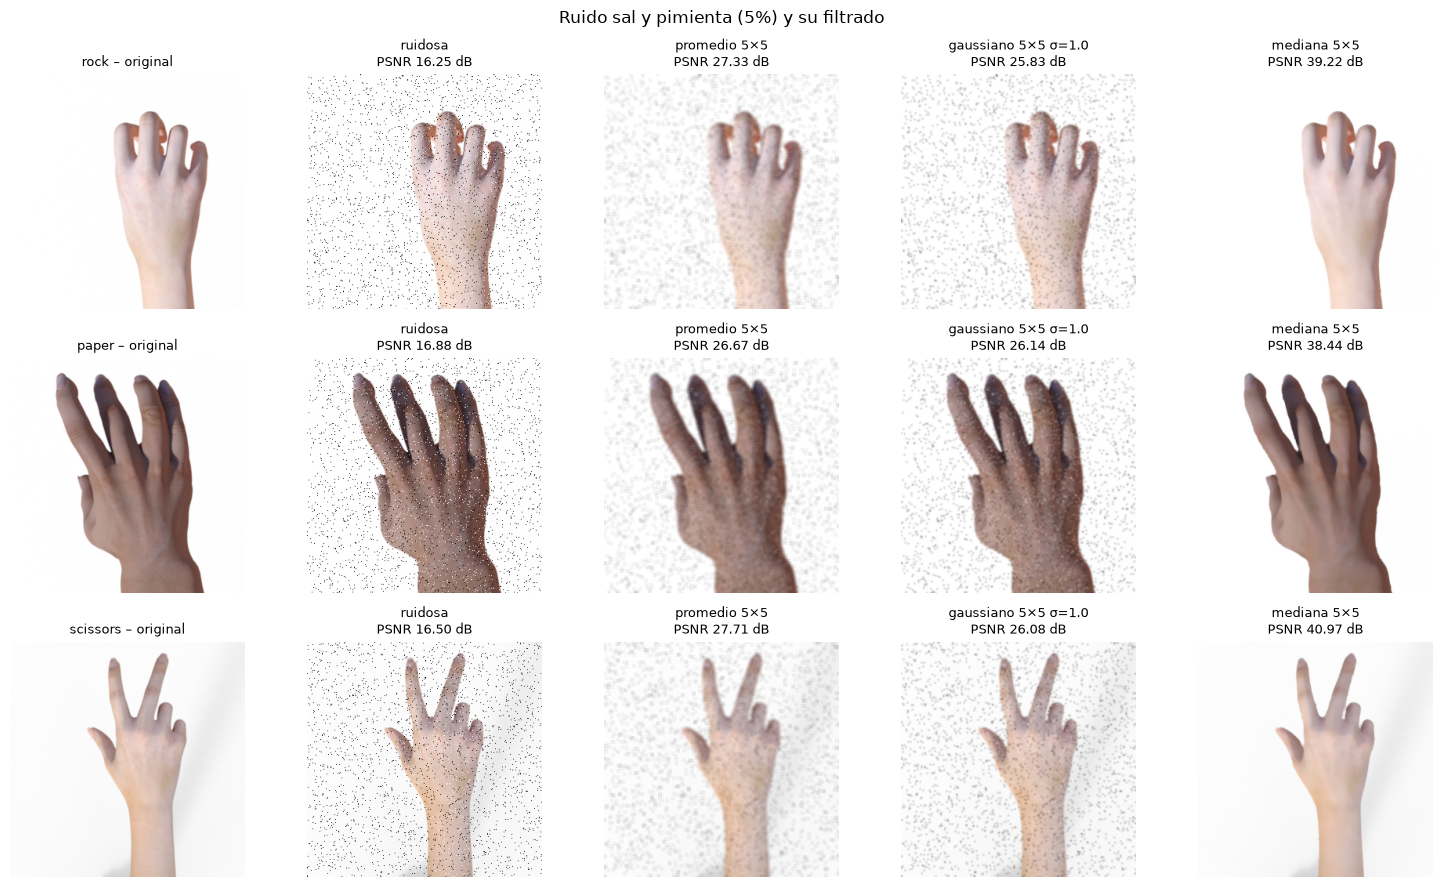

,ruidosa,promedio 5×5,gaussiano 5×5 σ=1.0,mediana 5×5
clase,,,,
rock,16.25,27.33,25.83,39.22
paper,16.88,26.67,26.14,38.44
scissors,16.50,27.71,26.08,40.97
promedio de clases,16.54,27.24,26.02,39.54


Mejor filtro por clase (mayor PSNR): {'rock': 'mediana 5×5', 'paper': 'mediana 5×5', 'scissors': 'mediana 5×5', 'promedio de clases': 'mediana 5×5'}


In [11]:
def agregar_sal_pimienta(img, prop, rng):
    """Devuelve una copia con una proporción `prop` de píxeles puestos en 0 o 255 (mitad y mitad)."""
    ruidosa = img.copy()
    alto, ancho = img.shape[:2]
    afectados = rng.random((alto, ancho)) < prop
    sal = rng.random((alto, ancho)) < 0.5
    ruidosa[afectados & sal] = 255
    ruidosa[afectados & ~sal] = 0
    return ruidosa


rng = np.random.default_rng(SEMILLA)
grilla, titulos, filas_psnr = [], [], []
for r in primeras:
    original = r["pixeles"]
    ruidosa = agregar_sal_pimienta(original, PROP_RUIDO, rng)
    resultados = {"ruidosa": ruidosa} | {nombre: f(ruidosa) for nombre, f in FILTROS.items()}
    grilla += [original] + list(resultados.values())
    titulos += [f"{r['clase']} – original"] + [
        f"{nombre}\nPSNR {cv2.PSNR(original, img):.2f} dB" for nombre, img in resultados.items()
    ]
    filas_psnr.append({"clase": r["clase"]} | {nombre: round(cv2.PSNR(original, img), 2) for nombre, img in resultados.items()})

mostrar_grilla(grilla, titulos, filas=3, columnas=5,
               titulo_figura=f"Ruido sal y pimienta ({PROP_RUIDO:.0%}) y su filtrado")
tabla_psnr = pd.DataFrame(filas_psnr).set_index("clase")
tabla_psnr.loc["promedio de clases"] = tabla_psnr.mean().round(2)
display(tabla_psnr)
print("Mejor filtro por clase (mayor PSNR):", tabla_psnr.drop(columns="ruidosa").idxmax(axis=1).to_dict())

**Interpretación.** El ruido sal y pimienta al 5 % baja la PSNR a unos **16,5 dB** en promedio. Los resultados promedio por clase son:

| Filtro | PSNR promedio |
|---|---|
| Mediana 5×5 | **39,54 dB** |
| Promedio 5×5 | 27,24 dB |
| Gaussiano 5×5 | 26,02 dB |

La mediana es el mejor filtro **en las tres clases** (38,44–40,97 dB), unos 12 dB por encima de los filtros lineales. Visualmente elimina casi todos los puntos y conserva los bordes. Los filtros lineales no eliminan los impulsos: los **reparten** sobre la ventana, y en el fondo blanco quedan manchas grises, además del desenfoque de los contornos.

Un detalle que muestra la tabla: el gaussiano obtiene **menor** PSNR que el promedio (26,02 vs. 27,24 dB). La causa es que, con σ = 1, el kernel gaussiano da un peso de 0,162 al píxel central frente a 1/25 = 0,04 del promedio. Si el píxel central es un impulso (0 o 255), el gaussiano lo diluye menos. Para ruido impulsivo, el filtro no lineal es la opción adecuada. Los filtros lineales son más apropiados para ruido gaussiano (pequeñas variaciones en todos los píxeles).

## 7. Transformaciones geométricas

Se implementan las tres transformaciones con los parámetros de la §1: rotación de 45° alrededor del
centro, traslación de (60, 60) px y escalado ×0,5. Rotación y traslación conservan el tamaño del
lienzo (300×300) y rellenan con blanco lo que queda descubierto; el escalado cambia las dimensiones.

In [12]:
def rotar(img):
    """Rota ANGULO grados (antihorario) alrededor del centro, conservando el tamaño y rellenando con blanco."""
    alto, ancho = img.shape[:2]
    matriz = cv2.getRotationMatrix2D((ancho / 2, alto / 2), ANGULO, 1.0)
    return cv2.warpAffine(img, matriz, (ancho, alto), borderMode=cv2.BORDER_CONSTANT, borderValue=COLOR_BORDE)


def trasladar(img):
    """Desplaza TX píxeles a la derecha y TY hacia abajo, rellenando con blanco."""
    alto, ancho = img.shape[:2]
    matriz = np.float32([[1, 0, TX], [0, 1, TY]])
    return cv2.warpAffine(img, matriz, (ancho, alto), borderMode=cv2.BORDER_CONSTANT, borderValue=COLOR_BORDE)


def escalar(img, factor=FACTOR_ESCALA):
    """Redimensiona por `factor` (INTER_AREA al reducir, INTER_LINEAR al ampliar)."""
    interpolacion = cv2.INTER_AREA if factor < 1 else cv2.INTER_LINEAR
    return cv2.resize(img, None, fx=factor, fy=factor, interpolation=interpolacion)


TRANSFORMACIONES = {
    f"rotación {ANGULO}°": rotar,
    f"traslación ({TX}, {TY}) px": trasladar,
    f"escalado ×{FACTOR_ESCALA}": escalar,
}

print("Matriz de rotación (300×300):")
print(np.round(cv2.getRotationMatrix2D((150, 150), ANGULO, 1.0), 3))
print("Matriz de traslación:")
print(np.float32([[1, 0, TX], [0, 1, TY]]))

Matriz de rotación (300×300):
[[  0.707   0.707 -62.132]
 [ -0.707   0.707 150.   ]]
Matriz de traslación:
[[ 1.  0. 60.]
 [ 0.  1. 60.]]


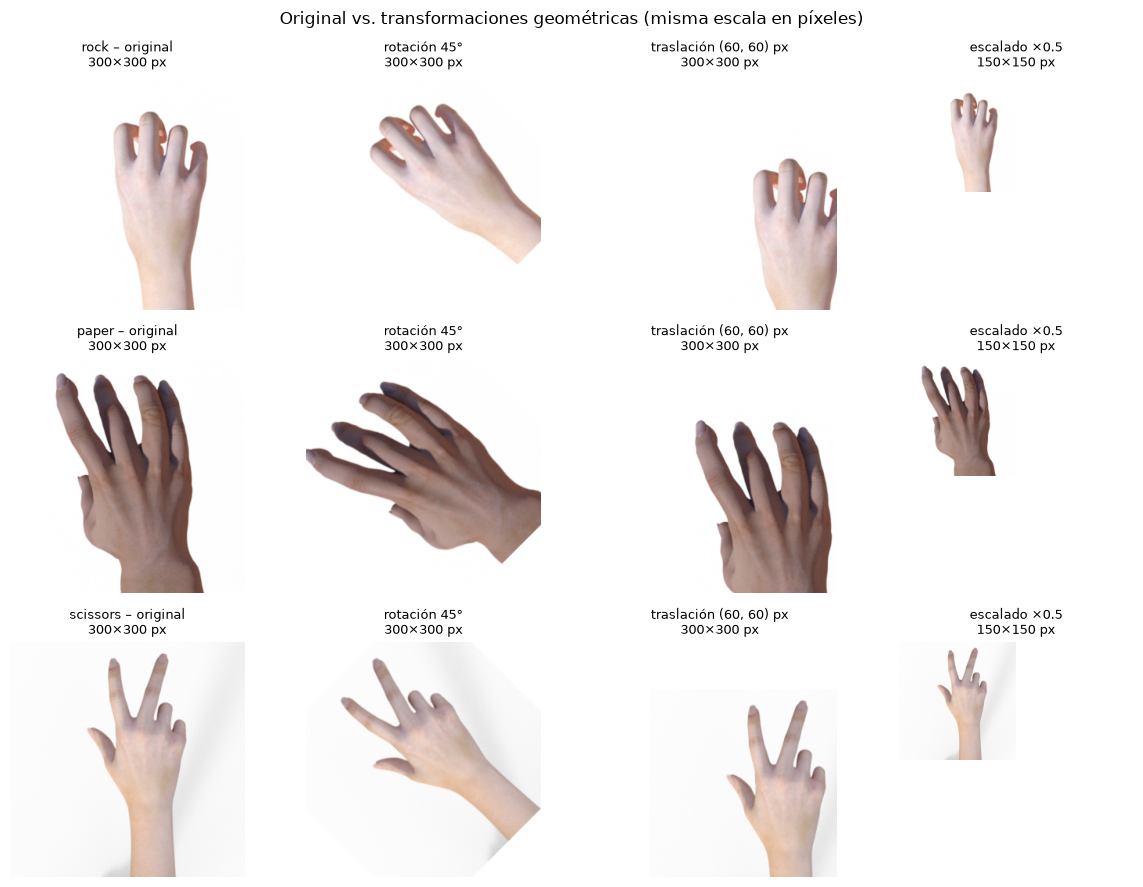

original (ancho×alto) resultado (ancho×alto)
clase    operación                                                          
rock     rotación 45°                         300×300                300×300
         traslación (60, 60) px               300×300                300×300
         escalado ×0.5                        300×300                150×150
paper    rotación 45°                         300×300                300×300
         traslación (60, 60) px               300×300                300×300
         escalado ×0.5                        300×300                150×150
scissors rotación 45°                         300×300                300×300
         traslación (60, 60) px               300×300                300×300
         escalado ×0.5                        300×300                150×150

In [13]:
grilla, titulos, filas_dim = [], [], []
for r in primeras:
    original = r["pixeles"]
    grilla.append(original)
    titulos.append(f"{r['clase']} – original\n{original.shape[1]}×{original.shape[0]} px")
    for nombre, t in TRANSFORMACIONES.items():
        resultado = t(original)
        grilla.append(resultado)
        titulos.append(f"{nombre}\n{resultado.shape[1]}×{resultado.shape[0]} px")
        filas_dim.append({"clase": r["clase"], "operación": nombre,
                          "original (ancho×alto)": f"{original.shape[1]}×{original.shape[0]}",
                          "resultado (ancho×alto)": f"{resultado.shape[1]}×{resultado.shape[0]}"})
# lienzo=300: todas se dibujan a la misma escala en píxeles, así el escalado ×0,5 se ve más pequeño
mostrar_grilla(grilla, titulos, filas=3, columnas=4, lienzo=300,
               titulo_figura="Original vs. transformaciones geométricas (misma escala en píxeles)")
display(pd.DataFrame(filas_dim).set_index(["clase", "operación"]))

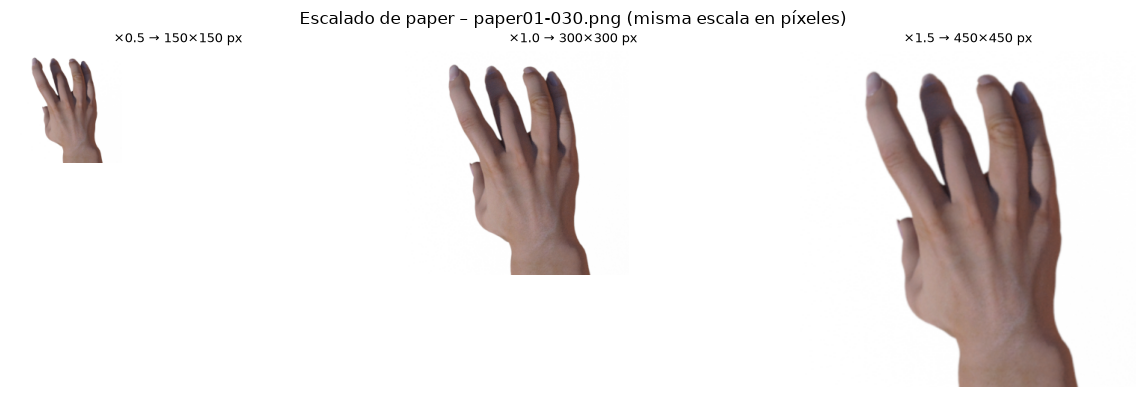

In [14]:
# Contraste: reducción ×0,5 (INTER_AREA) vs. ampliación ×1,5 (INTER_LINEAR). La ampliación NO se guarda.
r0 = primeras[1]
versiones = [escalar(r0["pixeles"], FACTOR_ESCALA), r0["pixeles"], escalar(r0["pixeles"], FACTOR_AMPLIACION)]
mostrar_grilla(
    versiones,
    [f"×{f} → {v.shape[1]}×{v.shape[0]} px" for f, v in zip((FACTOR_ESCALA, 1.0, FACTOR_AMPLIACION), versiones)],
    filas=1, columnas=3, lienzo=450, tam_celda=4.0,
    titulo_figura=f"Escalado de {r0['clase']} – {r0['nombre']} (misma escala en píxeles)",
)

**Interpretación.**

- **Rotación 45°**: la mano se inclina alrededor del centro de la imagen. Como el lienzo conserva 300×300 px, las **esquinas de la imagen original quedan fuera** y se recorta parte de la muñeca. Las cuatro esquinas del nuevo lienzo, sin píxel de origen, se rellenan de blanco y forman un octógono, apenas visible donde el fondo original ya era blanco. En las imágenes con sombra gris (p. ej., *scissors*) el borde del relleno sí se nota.
- **Traslación (60, 60) px**: la mano se desplaza hacia abajo a la derecha. Aparece una franja blanca de 60 px arriba y a la izquierda, y se pierden 60 px de contenido por el borde inferior y derecho (puntas de la muñeca o los dedos).
- **Escalado ×0,5**: la imagen pasa a **150×150 px**, un cuarto de los píxeles. La forma del gesto se mantiene reconocible, pero se pierden los detalles finos (uñas, nudillos). Con `INTER_AREA` no aparece *aliasing*. La ampliación ×1,5 (450×450 px, solo demostrativa) no agrega información: interpola los valores existentes y se ve ligeramente más suave.

Estas tres transformaciones no cambian la **clase** de la imagen (un puño rotado sigue siendo *rock*). Por eso son la base del **aumento de datos** (*data augmentation*): enseñan a un clasificador que el gesto no depende de su orientación, posición ni tamaño en la imagen.

## 8. Generación del nuevo conjunto

Se aplican las **6 operaciones a las 30 imágenes originales**. Cada resultado se guarda como PNG (sin
pérdida) en `output/<operación>/<clase>/<nombre_original>.png`, de modo que el nuevo conjunto
conserva la estructura de carpetas por clase y puede usarse directamente, por ejemplo, para
aumentar datos de un clasificador. La carpeta `output/` se borra y se recrea en cada ejecución para
que su contenido corresponda siempre al código actual.

In [15]:
OPERACIONES = {
    "promedio": filtro_promedio,
    "gaussiano": filtro_gaussiano,
    "mediana": filtro_mediana,
    "rotacion": rotar,
    "traslacion": trasladar,
    "escalado": escalar,
}

shutil.rmtree(DIR_SALIDA, ignore_errors=True)
for operacion, funcion in OPERACIONES.items():
    for r in imagenes:
        resultado = funcion(r["pixeles"])
        if resultado.shape == r["pixeles"].shape:
            assert not np.array_equal(resultado, r["pixeles"]), f"{operacion} no modificó {r['nombre']}"
        destino = DIR_SALIDA / operacion / r["clase"]
        destino.mkdir(parents=True, exist_ok=True)
        assert cv2.imwrite(str(destino / r["nombre"]), resultado), f"No se pudo escribir {destino / r['nombre']}"
    print(f"{operacion:<11} → {len(imagenes)} imágenes escritas en {DIR_SALIDA / operacion}/<clase>/")

promedio    → 30 imágenes escritas en output/promedio/<clase>/
gaussiano   → 30 imágenes escritas en output/gaussiano/<clase>/
mediana     → 30 imágenes escritas en output/mediana/<clase>/
rotacion    → 30 imágenes escritas en output/rotacion/<clase>/
traslacion  → 30 imágenes escritas en output/traslacion/<clase>/
escalado    → 30 imágenes escritas en output/escalado/<clase>/


## 9. Resumen y verificación

El conteo se hace **leyendo los archivos del disco**, no desde memoria, para comprobar que el nuevo
conjunto realmente existe.

In [16]:
archivos = sorted(DIR_SALIDA.glob("*/*/*.png"))
conteo = (
    pd.DataFrame({"operación": p.parts[-3], "clase": p.parts[-2]} for p in archivos)
    .value_counts()
    .unstack("operación")
    .reindex(index=list(CLASES), columns=list(OPERACIONES))
    .fillna(0)
    .astype(int)
)
conteo["total"] = conteo.sum(axis=1)
conteo.loc["total"] = conteo.sum()
display(conteo)

esperado = len(CLASES) * N_POR_CLASE * len(OPERACIONES)
assert (conteo.loc[list(CLASES), list(OPERACIONES)] == N_POR_CLASE).all().all(), "Hay celdas con un conteo distinto de N_POR_CLASE"
assert len(archivos) == esperado, f"Se esperaban {esperado} archivos y hay {len(archivos)}"

for operacion in OPERACIONES:
    leida = cv2.imread(str(DIR_SALIDA / operacion / imagenes[0]["clase"] / imagenes[0]["nombre"]), cv2.IMREAD_COLOR)
    esperada = (150, 150, 3) if operacion == "escalado" else (300, 300, 3)
    assert leida is not None and leida.shape == esperada, f"{operacion}: forma {None if leida is None else leida.shape}"

print(f"Originales: {len(imagenes)}  →  imágenes nuevas generadas: {len(archivos)} (= {len(CLASES)} clases × {N_POR_CLASE} × {len(OPERACIONES)} operaciones)")

operación,promedio,gaussiano,mediana,rotacion,traslacion,escalado,total
clase,,,,,,,
rock,10,10,10,10,10,10,60
paper,10,10,10,10,10,10,60
scissors,10,10,10,10,10,10,60
total,30,30,30,30,30,30,180


Originales: 30  →  imágenes nuevas generadas: 180 (= 3 clases × 10 × 6 operaciones)


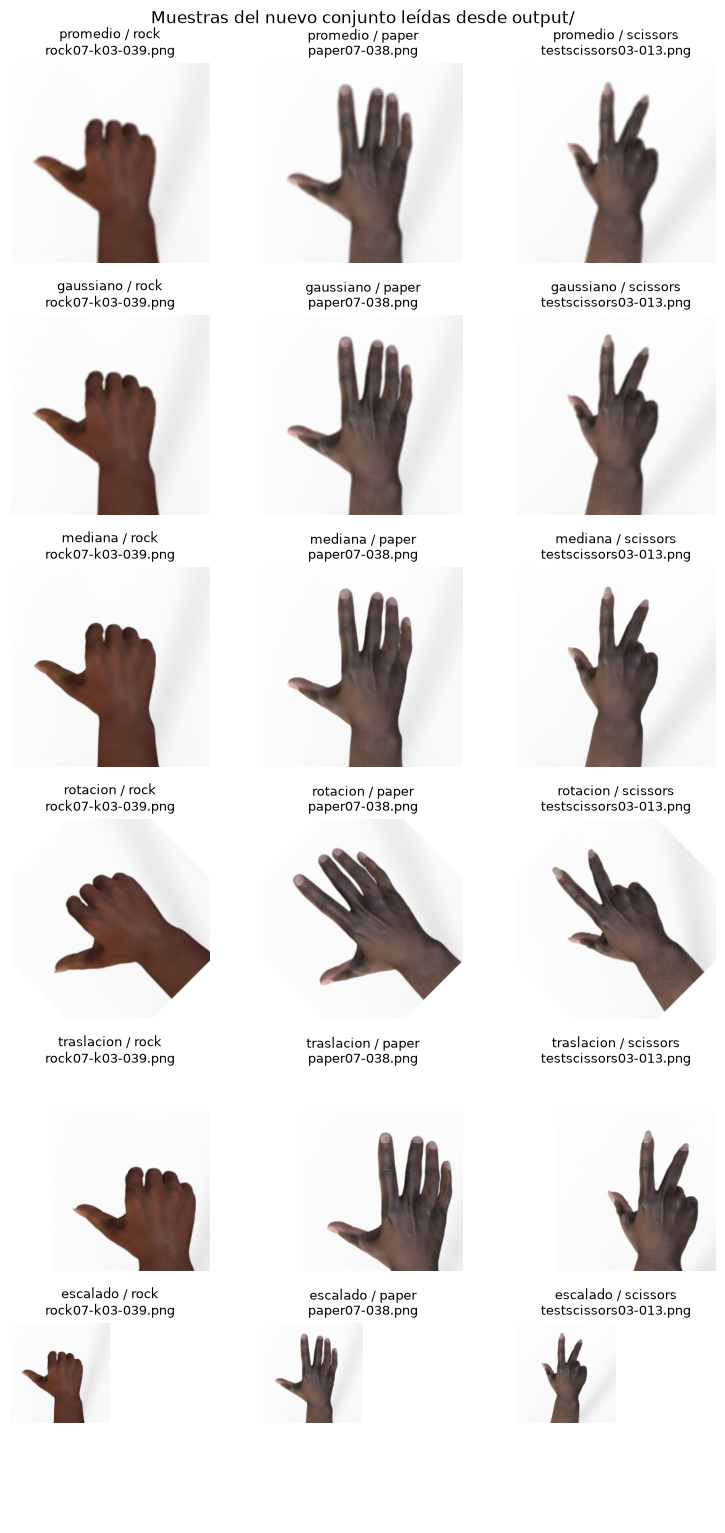

In [17]:
leidas, titulos = [], []
for operacion in OPERACIONES:
    for clase in CLASES:
        ruta = sorted((DIR_SALIDA / operacion / clase).glob("*.png"))[-1]
        leidas.append(cv2.imread(str(ruta), cv2.IMREAD_COLOR))
        titulos.append(f"{operacion} / {clase}\n{ruta.name}")
mostrar_grilla(leidas, titulos, filas=len(OPERACIONES), columnas=len(CLASES), lienzo=300, tam_celda=2.6,
               titulo_figura="Muestras del nuevo conjunto leídas desde output/")

## 10. Conclusiones

1. Se tomó un conjunto de imágenes de un problema real de visión, el reconocimiento de gestos de *piedra, papel o tijera*, con **3 clases en carpetas separadas** (10 imágenes por clase). Se le aplicaron las **seis operaciones** pedidas. Resultado: **30 imágenes originales → 180 imágenes nuevas** en `output/<operación>/<clase>/`, verificadas desde el disco (§9).
2. **Filtro promedio**: suavizado fuerte y uniforme. Reduce ruido de forma general, a costa de desenfocar los bordes (§5).
3. **Filtro gaussiano**: suavizado ponderado que preserva mejor las estructuras que el promedio con la misma ventana. Es adecuado como paso previo a la detección de bordes o para atenuar ruido gaussiano. Frente al ruido impulsivo fue el menos eficaz (26,02 dB, §6).
4. **Filtro de mediana (no lineal)**: se comprobó que no cumple superposición (diferencia de hasta 48 niveles, §5). Fue claramente el mejor contra el ruido sal y pimienta (39,54 dB frente a 27,24 y 26,02 dB) y conserva bordes nítidos (§6).
5. **Rotación, traslación y escalado** cambian la geometría sin cambiar la clase. Sirven para generar variaciones realistas (aumento de datos) y para normalizar tamaños, por ejemplo al reducir a 150×150 para un modelo más liviano (§7).

**Limitaciones**: las imágenes son sintéticas (CGI) y casi sin ruido, por lo que el efecto de los filtros se evaluó con ruido artificial. Los parámetros son fijos (no se exploraron otros tamaños de kernel, σ ni ángulos). El subconjunto es pequeño (30 imágenes) y es una demostración, no una muestra representativa. La rotación sin ampliar el lienzo recorta las esquinas, y la traslación pierde 60 px de contenido.